# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

os.environ["JAX_PLATFORM_NAME"] = "cpu"  # must be set before importing jax

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-02-27 19:34:58,219:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-02-27 19:34:58,219 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-02-27 19:34:58,576 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux
import skewerjax.utils.plotting_tools as pt

import skewerjax.optical_depth.optical_depth as od

from skewerjax.constants.physical_constants import phys

# Auxiliary objects that would be employed throughout the notebook

### Define radiation domination cosmology to employ in the different examples that require it

In [3]:
# Create cosmology object
cosmology = Cosmology(
    H0=phys.H0,
    Omega_r_0=0.0,  # Radiation density (CMB + neutrinos)
    Omega_m_0=1.0,
    Omega_k_0=0.0,
    Omega_lambda_0=0.0,
)

# Define which cosmology to use, this is set as default to 0 since skewer and cosmology objects can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time

ii_cosmology = 0

### Define wavelength range and lines to study

In [4]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "SiIII-1206"])

### Auxiliary variables

In [5]:
L_box = 300.0  # Mpc

T0 = 5e5

n0_min = 1e-16
n0_max = 1e-10

def pk_template(k: jnp.ndarray, A, n, k0, k_cut):
    # P(k) = A (k/k0)^n exp[-(k/k_cut)^2]
    kk = jnp.maximum(k, 1e-12)
    return A * (kk / k0) ** n * jnp.exp(-(kk / k_cut) ** 2)

number_density_sampler = toy_samplers.number_density_sampler_gaussian_3d(
    key=jax.random.PRNGKey(0),
    pk_of_k=lambda k: pk_template(k, A=5.0, n=-2.5, k0=2.0, k_cut=50.0),
    n0_min=n0_min, n0_max=n0_max, L_box=L_box,
    grid_shape=(256, 256, 256), contrast=1.2,
)

In [6]:
fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0, T0, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0, T0, L_box)),    # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
})

In [7]:
delta_lambda_limits = 10.0
min_lambda = jnp.min(line_bundle.lambda0_A) - delta_lambda_limits
max_lambda = 1315.0

resolution_lambda_A = 1.0 # in Angstroms
N_lambda = int((max_lambda - min_lambda) / resolution_lambda_A)

wavelengths = jnp.linspace(min_lambda, max_lambda, N_lambda)  # in Angstroms

# Generate figures for gif

In [ ]:
save_path_global = "/home/STORAGE/SKEWERS/PLOTS/toy_metals/"
os.makedirs(save_path_global, exist_ok=True)

N_imshow = 1024
points_grid_imshow = aux.make_plane_points(L_box, 'x', L_box/2, N_imshow, N_imshow)
log10_number_density_imshow = np.log10(fields.number_density(jnp.concatenate([jnp.ones((N_imshow, N_imshow, 1)), points_grid_imshow], axis=-1)))

N_grid_skewers = 3
N_ppsk = N_imshow
points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y")

ic = N_grid_skewers//2
jc = N_grid_skewers//2

density_norm = mpl.colors.Normalize(
    vmin=float(np.min(log10_number_density_imshow)),
    vmax=float(np.max(log10_number_density_imshow)),
)

skewer_cmap = mpl.cm.get_cmap("gist_rainbow")
skewer_norm = mpl.colors.Normalize(vmin=0.0, vmax=float(N_ppsk - 1))

L_box = float(points_grid_imshow[..., 1].max() - points_grid_imshow[..., 1].min())

list_plot = range(1, N_ppsk, 8) # plot one each 2 N_ppsk
list_plot = [N_ppsk-1]
for ii in list_plot:

    _N_ppsk = ii + 1
    _points_grid_skewers = points_grid_skewers[:, :, 0:_N_ppsk, :]

    _points = jnp.reshape(_points_grid_skewers, (N_grid_skewers*N_grid_skewers, _N_ppsk, 3))
    
    skewer_bundle = SkewerBundle(spatial_points=_points, cosmologies=cosmology)
    optical_depth = od.compute_optical_depth(skewer_bundle, wavelengths, line_bundle, fields) # Compute optical depth
    F_over_F0 = jnp.reshape(jnp.exp(-optical_depth), (line_bundle.n_lines, N_grid_skewers, N_grid_skewers, len(wavelengths)))

    points_central = skewer_bundle.spatial_points[ic * N_grid_skewers + jc]
    log10_number_density_central = np.log10(fields.number_density(jnp.concatenate([jnp.ones(points_central.shape[0:1])[..., None], points_central], axis=-1)))
    F_over_F0_central = F_over_F0[..., ic * N_grid_skewers + jc]

    fig1, axes1 = pt.plot_density_imshow_and_central_profile(
        points_central=np.asarray(points_central),
        points_grid_imshow=np.asarray(points_grid_imshow),
        log10_number_density_imshow=np.asarray(log10_number_density_imshow),
        log10_number_density_central=np.asarray(log10_number_density_central),
        line_bundle=line_bundle,
        savepath_png=os.path.join(save_path_global, f"density_{ii}.png"),
        density_norm=density_norm,
        box_limits_yz=((0.0, L_box), (0.0, L_box)),
        box_limits_los=(0.0, L_box),
        skewer_cmap=skewer_cmap,
        skewer_norm=skewer_norm,
        show=False,
    )

    fig2, axes2 = pt.plot_flux_panels(
        wavelengths=np.asarray(wavelengths),
        F_over_F0=np.asarray(F_over_F0),
        ic=ic, jc=jc,
        line_bundle=line_bundle,
        savepath_png=os.path.join(save_path_global, f"flux_split_{ii}.png"),
        skewer_cmap=skewer_cmap,
        skewer_norm=skewer_norm,
        skewer_last_index=ii,  # "last" point shown in this iteration
        show=False,
    )

    fig, ax = pt.plot_flux_panels_colored_by_los(
        wavelengths=np.asarray(wavelengths),
        F_over_F0=np.asarray(F_over_F0),
        ic=ic, jc=jc,
        line_bundle=line_bundle,
        skewer_bundle=skewer_bundle,
        N_grid_skewers=N_grid_skewers,
        skewer_cmap=skewer_cmap,
        skewer_norm=skewer_norm,
        savepath_png=os.path.join(save_path_global, f"flux_combined_{ii}.png"),
        show=False,
    )

In [ ]:
linestyles = ["-", "--", "-.", ":"]

_scale_factors = np.asarray(skewer_bundle.scale_factors[0, ic * N_grid_skewers + jc], dtype=float)
a0 = float(_scale_factors[0])
a_last = float(_scale_factors[-1])

fig, ax = plt.subplots(figsize=(10, 4.5))

legend_handles, legend_labels = [], []

for i_line, line in enumerate(line_bundle.lines):
    ls = linestyles[i_line % len(linestyles)]
    lambda0 = float(line.lambda0_A)
    lambda0_f = lambda0 * a_last / a0

    # vertical markers: same linestyle as the line
    ax.axvline(lambda0,   color="grey", linestyle=ls, linewidth=1.5, alpha=0.95, zorder=1)
    ax.axvline(lambda0_f, color="grey", linestyle=ls, linewidth=1.5, alpha=0.95, zorder=1)
    ax.plot(wavelengths, F_over_F0[i_line, ic, jc, :], color="k", lw=1.5, linestyle=ls, zorder=2)

    name = getattr(line, "name", None) or getattr(line, "label", None) or f"Line {i_line}"
    legend_handles.append(Line2D([0], [0], color="k", lw=2.2, linestyle=ls))
    legend_labels.append(name)

ax.set_xlim(float(np.min(wavelengths)), float(np.max(wavelengths)))
ax.set_ylim([-0.05, 1.05])

ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$", fontsize=20)
ax.set_ylabel(r"$e^{-\tau}$", fontsize=20)

ax.tick_params(which="both", direction="in", top=True, right=True, length=7, width=1.6, labelsize=18)
ax.tick_params(which="minor", length=4)
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

ax.legend(
    legend_handles, legend_labels, loc="lower right", fontsize=16, handlelength=2.6, handletextpad=0.6, borderaxespad=0.6, ncols=1
)

fig.tight_layout()

savepath_png = os.path.join(save_path_global, "flux_black.png")
d = os.path.dirname(savepath_png)
if d:
    os.makedirs(d, exist_ok=True)
fig.savefig(savepath_png, dpi=200, bbox_inches="tight")

plt.show()

In [ ]:
optical_depth_total = jnp.sum(optical_depth, axis=0)

In [ ]:
linestyles = ["-", "--", "-.", ":"]

_scale_factors = np.asarray(skewer_bundle.scale_factors[0, ic * N_grid_skewers + jc], dtype=float)
a0 = float(_scale_factors[0])
a_last = float(_scale_factors[-1])

fig, ax = plt.subplots(figsize=(10, 4.5))

legend_handles, legend_labels = [], []

for i_line, line in enumerate(line_bundle.lines):
    ls = linestyles[i_line % len(linestyles)]
    lambda0 = float(line.lambda0_A)
    lambda0_f = lambda0 * a_last / a0

    # vertical markers: same linestyle as the line
    ax.axvline(lambda0,   color="grey", linestyle=ls, linewidth=1.5, alpha=0.95, zorder=1)
    ax.axvline(lambda0_f, color="grey", linestyle=ls, linewidth=1.5, alpha=0.95, zorder=1)

ax.plot(wavelengths, jnp.exp(-optical_depth_total[ic * N_grid_skewers + jc, :]), color="k", lw=1.5, linestyle='-', zorder=2)

ax.set_xlim(float(np.min(wavelengths)), float(np.max(wavelengths)))
ax.set_ylim([-0.05, 1.05])

ax.set_xlabel(r"Wavelength $\lambda\ [\mathrm{\AA}]$", fontsize=20)
ax.set_ylabel(r"$e^{-\tau}$", fontsize=20)

ax.tick_params(which="both", direction="in", top=True, right=True, length=7, width=1.6, labelsize=18)
ax.tick_params(which="minor", length=4)
for spine in ax.spines.values():
    spine.set_linewidth(1.8)

fig.tight_layout()

savepath_png = os.path.join(save_path_global, "flux_total.png")
d = os.path.dirname(savepath_png)
if d:
    os.makedirs(d, exist_ok=True)
fig.savefig(savepath_png, dpi=200, bbox_inches="tight")

plt.show()

# Compute $\xi$

In [8]:
N_grid_skewers = 36
N_ppsk = 1024
points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y")
points = jnp.reshape(points_grid_skewers, (N_grid_skewers*N_grid_skewers, N_ppsk, 3))
skewer_bundle = SkewerBundle(spatial_points=points, cosmologies=cosmology)

2026-02-27 19:35:09,522 - INFO - Initializing SkewerBundle with 1296 skewers, 1024 points per skewer
2026-02-27 19:35:09,568 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 1296 skewers
2026-02-27 19:35:09,585 - INFO - All skewers set to absorption mode
2026-02-27 19:35:09,635 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-02-27 19:35:09,840 - INFO - Computing comoving distances along skewer direction
2026-02-27 19:35:09,992 - INFO - Computing scale factors from cosmology
2026-02-27 19:35:11,451 - INFO - Storing quadri-vectors
2026-02-27 19:35:11,510 - INFO - SkewerBundle initialization complete


In [9]:
delta_lambda_limits = 10.0
min_lambda = jnp.min(line_bundle.lambda0_A) - delta_lambda_limits
max_lambda = jnp.max(line_bundle.lambda0_A) * (skewer_bundle.a0.max() / skewer_bundle.scale_factors.min()) + delta_lambda_limits

resolution_lambda_A = 0.05 # in Angstroms
N_lambda = int((max_lambda - min_lambda) / resolution_lambda_A)

wavelengths = jnp.linspace(min_lambda, max_lambda, N_lambda)  # in Angstroms

In [10]:
array_size_bytes = N_lambda * skewer_bundle.N_sk * skewer_bundle.N_ppsk * line_bundle.n_lines * jnp.dtype(jnp.float64).itemsize
array_size_GB = array_size_bytes / 1e9
print(array_size_GB)

import psutil
memory_size = psutil.virtual_memory().total
memory_size_GB = memory_size / 1e9
print(memory_size_GB)

50.53612032
134.869372928


In [11]:
optical_depth = od.compute_optical_depth(skewer_bundle, wavelengths, line_bundle, fields) # Compute optical depth
F_over_F0 = jnp.exp(-optical_depth)

2026-02-27 19:35:11,609 - INFO - [OPTICAL_DEPTH] Starting computation for cosmology index 0, Voigt impl=ExoJAX
2026-02-27 19:35:11,609 - INFO - [OPTICAL_DEPTH] Extracting 1296 skewers with 1024 points each
2026-02-27 19:35:11,659 - INFO - [OPTICAL_DEPTH] Computing line profiles for 2 lines across 2 species
2026-02-27 19:35:15,202 - INFO - [OPTICAL_DEPTH] Line profiles computed with shape (2, 1296, 1024, 2380)
2026-02-27 19:35:15,204 - INFO - [OPTICAL_DEPTH] Tiling fields for 2 species to line-level
2026-02-27 19:36:17,103 - INFO - [OPTICAL_DEPTH] Tiled number_density with shape (2, 1296, 1024)
2026-02-27 19:36:17,104 - INFO - [OPTICAL_DEPTH] Computing dtau_dx with constant 2.654009e-03 nm²/ns
2026-02-27 19:36:17,463 - INFO - [OPTICAL_DEPTH] dtau_dx computed with shape (2, 1296, 1024, 2380)
2026-02-27 19:36:17,466 - INFO - [OPTICAL_DEPTH] Reorienting 1296 skewers based on photon path direction mask
2026-02-27 19:36:17,839 - INFO - [OPTICAL_DEPTH] Arrays reoriented: quadri_vectors (1296,

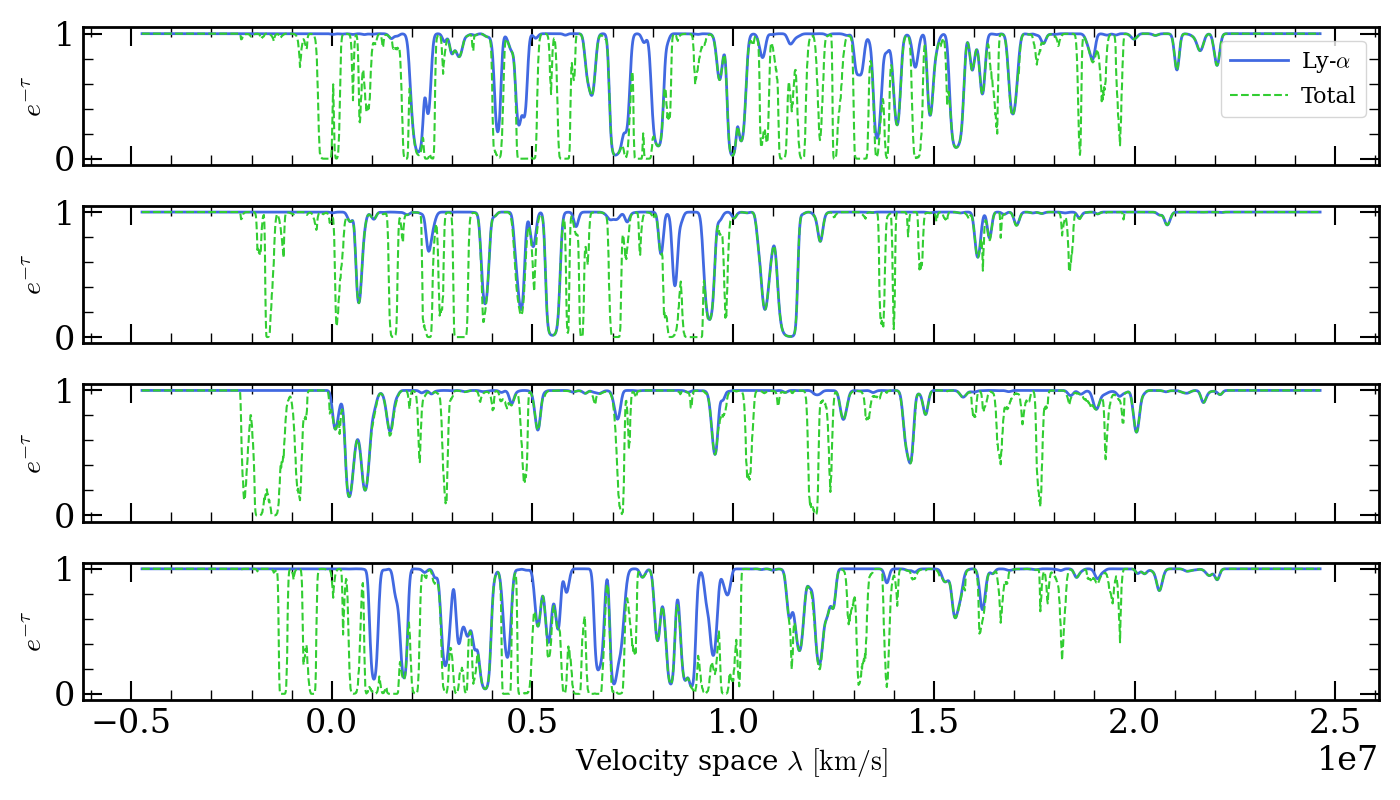

In [12]:
N_plot = 4
idxs_plot = np.random.choice(N_grid_skewers * N_grid_skewers, N_plot, replace=False)

fig, axes = plt.subplots(N_plot, 1, figsize=(14, 2*N_plot), sharex=True, sharey=True)

lambda0_Lya = line_bundle.lines_for_species('HI')[0].lambda0_A
x_velocities = phys.c * (wavelengths - lambda0_Lya) / lambda0_Lya # km/s

for ii, idx in enumerate(idxs_plot):

    ax = axes[ii]

    _F_Lya = F_over_F0[0, idx, :]
    ax.plot(x_velocities, _F_Lya, color='royalblue', lw=2.0, linestyle='-')

    _F = np.prod(F_over_F0[:, idx, :], axis=0)
    ax.plot(x_velocities, _F, color='limegreen', lw=1.5, linestyle='--')

    ax.set_ylim([-0.05, 1.05])

    ax.set_ylabel(r"$e^{-\tau}$", fontsize=20)

ax.set_xlabel(r"Velocity space $\lambda\ [\mathrm{km/s}]$", fontsize=20)

# custom legend
handle = Line2D([0], [0], color='royalblue', lw=2.0, linestyle='-', label=r'Ly-$\alpha$')
handle2 = Line2D([0], [0], color='limegreen', lw=1.5, linestyle='--', label='Total')
axes[0].legend(handles=[handle, handle2], loc='upper right', fontsize=16, handlelength=2.6, handletextpad=0.6, borderaxespad=0.6, ncols=1)

fig.tight_layout()
plt.show()

In [13]:
import skewerjax.summary_stats.xi1D as xi1D

In [14]:
lambda0_Lya = line_bundle.lines_for_species('HI')[0].lambda0_A
x_velocities = phys.c * (wavelengths - lambda0_Lya) / lambda0_Lya # km/s

In [15]:
print(F_over_F0[0].shape)
print(wavelengths.shape)

(1296, 2380)
(2380,)


In [16]:
# -----------------------
# Inputs
# -----------------------
x = np.asarray(wavelengths)                 # (2380,)
F1 = np.asarray(F_over_F0[0])               # (1024, 2380)
F2 = np.asarray(jnp.prod(F_over_F0, axis=0))# (1024, 2380)

# 2PCF settings
n_bins = 256
r_min = 0.0
r_max = float(x.max() - x.min())
include_self = False
center = True
standardize = False
chunk_size = 1 << 15

# Plot settings
n_show = 64                 # how many individual curves to show per case
xlim = (0.0, 30.0)          # set to None for full range

# -----------------------
# Compute 2PCF: Case 1
# -----------------------
r_centers_1, xi_1 = xi1D.two_point_corr_1d(
    jnp.asarray(x), jnp.asarray(F1), n_bins=n_bins, r_min=r_min, r_max=r_max, include_self=include_self,
    center=center, standardize=standardize, chunk_size=chunk_size,
)
r = np.asarray(r_centers_1)
xi1 = np.asarray(xi_1)
m1 = np.nanmean(xi1, axis=0)
s1 = np.nanstd(xi1, axis=0)

# -----------------------
# Compute 2PCF: Case 2
# -----------------------
r_centers_2, xi_2 = xi1D.two_point_corr_1d(
    jnp.asarray(x), jnp.asarray(F2), n_bins=n_bins, r_min=r_min, r_max=r_max, include_self=include_self,
    center=center, standardize=standardize, chunk_size=chunk_size,
)
r2 = np.asarray(r_centers_2)
xi2 = np.asarray(xi_2)
m2 = np.nanmean(xi2, axis=0)
s2 = np.nanstd(xi2, axis=0)

# Sanity check: same r grid
if not np.allclose(r, r2, atol=1e-12, rtol=0):
    raise ValueError("Different r_centers between cases. Ensure identical binning inputs.")

# -----------------------
# Apply x-range mask for plotting
# -----------------------
mask = np.ones_like(r, dtype=bool)
if xlim is not None:
    mask &= (r >= xlim[0]) & (r <= xlim[1])

# Subset of individual curves to plot
def pick_idx(n, k):
    if k <= 0:
        return np.array([], dtype=int)
    if k >= n:
        return np.arange(n, dtype=int)
    return np.linspace(0, n - 1, k, dtype=int)

idx1 = pick_idx(xi1.shape[0], n_show)
idx2 = pick_idx(xi2.shape[0], n_show)

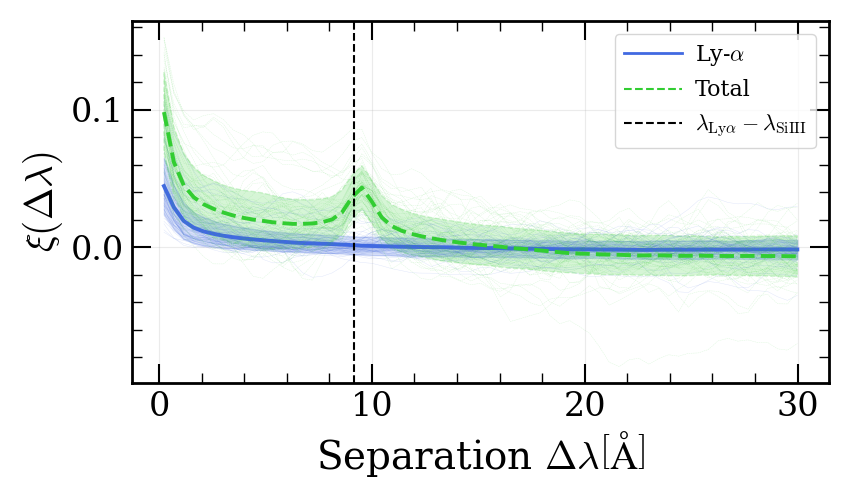

In [17]:
# -----------------------
# Single combined figure
# -----------------------
fig, ax = plt.subplots(figsize=(8.5, 5.0))

# Case 1
for i in idx1:
    ax.plot(r[mask], xi1[i, mask], alpha=0.18, linewidth=0.3, c='royalblue', ls='-')
ax.plot(r[mask], m1[mask], linewidth=2.8, c='royalblue', ls='-')
ax.fill_between(r[mask], (m1 - s1)[mask], (m1 + s1)[mask], alpha=0.2, color='royalblue', ls='-')

# Case 2
for i in idx2:
    ax.plot(r[mask], xi2[i, mask], alpha=0.18, linewidth=0.3, c='limegreen', ls='--')
ax.plot(r[mask], m2[mask], linewidth=2.8, c='limegreen', ls='--')
ax.fill_between(r[mask], (m2 - s2)[mask], (m2 + s2)[mask], alpha=0.2, color='limegreen', ls='--')

expected_cross_peak = line_bundle.lambda0_A[0] - line_bundle.lambda0_A[1]
ax.axvline(expected_cross_peak, c='k', ls='--', lw=1.5)

handle = Line2D([0], [0], color='royalblue', lw=2.0, linestyle='-', label=r'Ly-$\alpha$')
handle2 = Line2D([0], [0], color='limegreen', lw=1.5, linestyle='--', label='Total')
handle3 = Line2D([0], [0], color='k', lw=1.5, linestyle='--', label=r'$\lambda_{\mathrm{Ly}\alpha} - \lambda_{\mathrm{SiIII}}$')
ax.legend(handles=[handle, handle2, handle3], loc='upper right', fontsize=16, handlelength=2.6, handletextpad=0.6, borderaxespad=0.6, ncols=1)

ax.set_xlabel(r"Separation $\Delta\lambda \left[\mathrm{\AA}\right]$")
ax.set_ylabel(r"$\xi(\Delta\lambda)$")
ax.grid(True, alpha=0.25)
fig.tight_layout()
plt.show()